In [7]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    """Transforms the nested JSON from Open-Meteo into a tabular DataFrame."""
    df = pd.DataFrame(payload["hourly"])
    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    df["elevation"] = payload.get("elevation", 0.0)
    return df

In [8]:
# Search for all JSON files saved in the data/raw/ folder.
raw_files = list(Path("../data/raw").glob("*/*.json"))

dfs = []
for file_path in raw_files:
    with open(file_path, "r", encoding="utf-8") as f:
        payload = json.load(f)

    # Extracts the city name from the filename (e.g., london_20261110.json -> London)
    city_name = file_path.name.split("_")[0].capitalize()
    dfs.append(flatten(payload, city_name))

df_combined = pd.concat(dfs, ignore_index=True)
df_combined.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude,elevation
0,2026-11-08T00:00,8.0,88,6.3,0.0,5.0,3,Birmingham,52.488064,-1.879852,122.0
1,2026-11-08T01:00,7.7,90,6.3,0.0,3.2,3,Birmingham,52.488064,-1.879852,122.0
2,2026-11-08T02:00,7.7,92,6.6,0.0,1.8,3,Birmingham,52.488064,-1.879852,122.0
3,2026-11-08T03:00,7.6,93,6.5,0.0,1.4,3,Birmingham,52.488064,-1.879852,122.0
4,2026-11-08T04:00,7.4,94,6.4,0.0,1.1,3,Birmingham,52.488064,-1.879852,122.0


In [9]:
print("--- SHAPE ---")
print(df_combined.shape)

print("\n--- DTYPES ---")
print(df_combined.dtypes)

print("\n--- NULL VALUES ---")
print(df_combined.isna().sum())

print("\n--- STATISTICAL SUMMARY ---")
display(df_combined.describe())

print("\n--- DUPLICATES CHECK (city + time) ---")
duplicates_count = df_combined.duplicated(subset=["city", "time"]).sum()
print(f"Total duplicate rows: {duplicates_count}")

print("\n--- DISTINCT WEATHER CODES ---")
print(df_combined["weather_code"].value_counts())

--- SHAPE ---
(480, 11)

--- DTYPES ---
time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
elevation               float64
dtype: object

--- NULL VALUES ---
time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
elevation               0
dtype: int64

--- STATISTICAL SUMMARY ---


,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude,elevation
count,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000
mean,7.667500,87.404167,5.786667,0.006667,5.612083,4.237500,52.983547,-2.121237,56.000000
std,1.306362,6.569302,1.528678,0.046116,3.896272,9.454752,1.661466,1.122746,38.495289
min,3.600000,67.000000,1.000000,0.000000,0.400000,0.000000,51.480080,-3.192810,14.000000
25%,6.700000,84.000000,4.800000,0.000000,3.200000,2.000000,51.511470,-3.174713,23.000000
50%,7.700000,89.000000,5.900000,0.000000,4.700000,3.000000,52.488064,-2.228027,52.000000
75%,8.600000,92.000000,7.000000,0.000000,7.200000,3.000000,53.478767,-1.879852,69.000000
max,10.600000,100.000000,8.900000,0.400000,19.100000,51.000000,55.959354,-0.130783,122.000000



--- DUPLICATES CHECK (city + time) ---
Total duplicate rows: 240

--- DISTINCT WEATHER CODES ---
weather_code
3     274
2      90
0      48
1      48
51     14
45      6
Name: count, dtype: int64


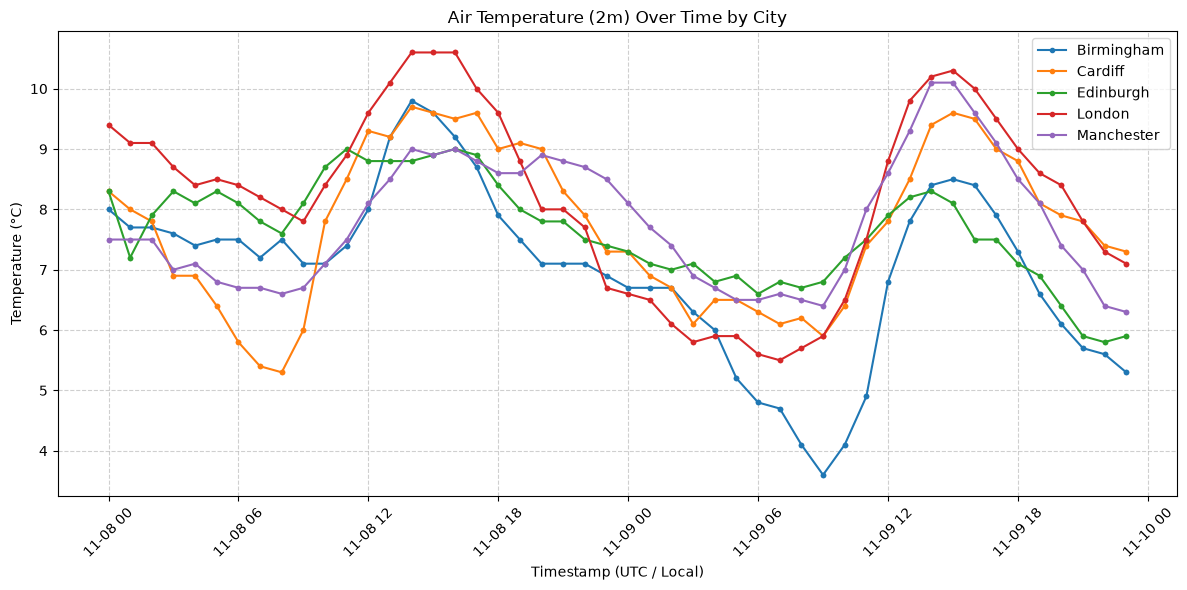

In [10]:
# Convert the time column to datetime for correct plotting
df_plot = df_combined.copy()
df_plot["time"] = pd.to_datetime(df_plot["time"])

plt.figure(figsize=(12, 6))
for city, group in df_plot.groupby("city"):
    # Sort by time before plotting.
    group = group.sort_values("time")
    plt.plot(group["time"], group["temperature_2m"], label=city, marker="o", markersize=3)

plt.title("Air Temperature (2m) Over Time by City")
plt.xlabel("Timestamp (UTC / Local)")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5 Key Exploratory Findings

1. **Timestamp Data Type:** `time` is ingested as a plain text string (`object`). It must be parsed to `datetime64[ns]` during the Transform step to enable time-series operations and sorting.
2. **Duplicate Records:** Executing the extraction pipeline multiple times generates overlapping `(city, time)` records. Deduplication based on `(city, time)` is mandatory before database insertion.
3. **Data Range Sanity:** Temperatures (`temperature_2m`) oscillate within expected ranges for November in the UK (approx. 3°C to 14°C), showing no anomalous outliers or corrupted values.
4. **WMO Weather Code Mapping:** `weather_code` contains numeric codes (e.g., 0 = Clear Sky, 3 = Overcast, 61 = Slight Rain). A translation dictionary is required to provide user-friendly descriptions.
5. **Dataset Grain:** The current table grain is **one row per city per hour**, with static attributes (`latitude`, `longitude`, `elevation`) duplicated across every hourly timestamp.